In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import model
import json, csv
import mvpy
import plots

In [2]:
'''
load config and data
'''

import hydra
from omegaconf import DictConfig, OmegaConf
from loguru import logger
from tqdm import tqdm

from os.path import join
from pathlib import Path
from bids import BIDSLayout

import pandas as pd
import numpy as np
import json, csv

import model

from typing import Tuple, Dict

import os
from hydra import initialize, initialize_config_module, initialize_config_dir, compose
from omegaconf import OmegaConf

# load config
with initialize(version_base=None, config_path="../conf"):
    cfg = compose(config_name = 'config.yaml', overrides = 
                  ['data=exp2', 'run=0', 'device=cpu',
                   'data.path=../data/ds-exp2/',
                   'data.resources=../data/resources/']
    )

# load data
data = model.dataset.Dataset(
    cfg, logger
).load()

# load arrangements
arrangements = data.load_arrangements(n_session = 1)

# set task
task = cfg.task.masubemb

# load demographics
X, L = arrangements.make_demographics(task.demographics, cfg)
X = X.cpu().numpy()

2026-11-18 15:21:32.567 | INFO     | model.dataset:load:1048 - Loading BIDS...
2026-11-18 15:21:32.576 | INFO     | model.dataset:load:1057 - Filtering subjects...


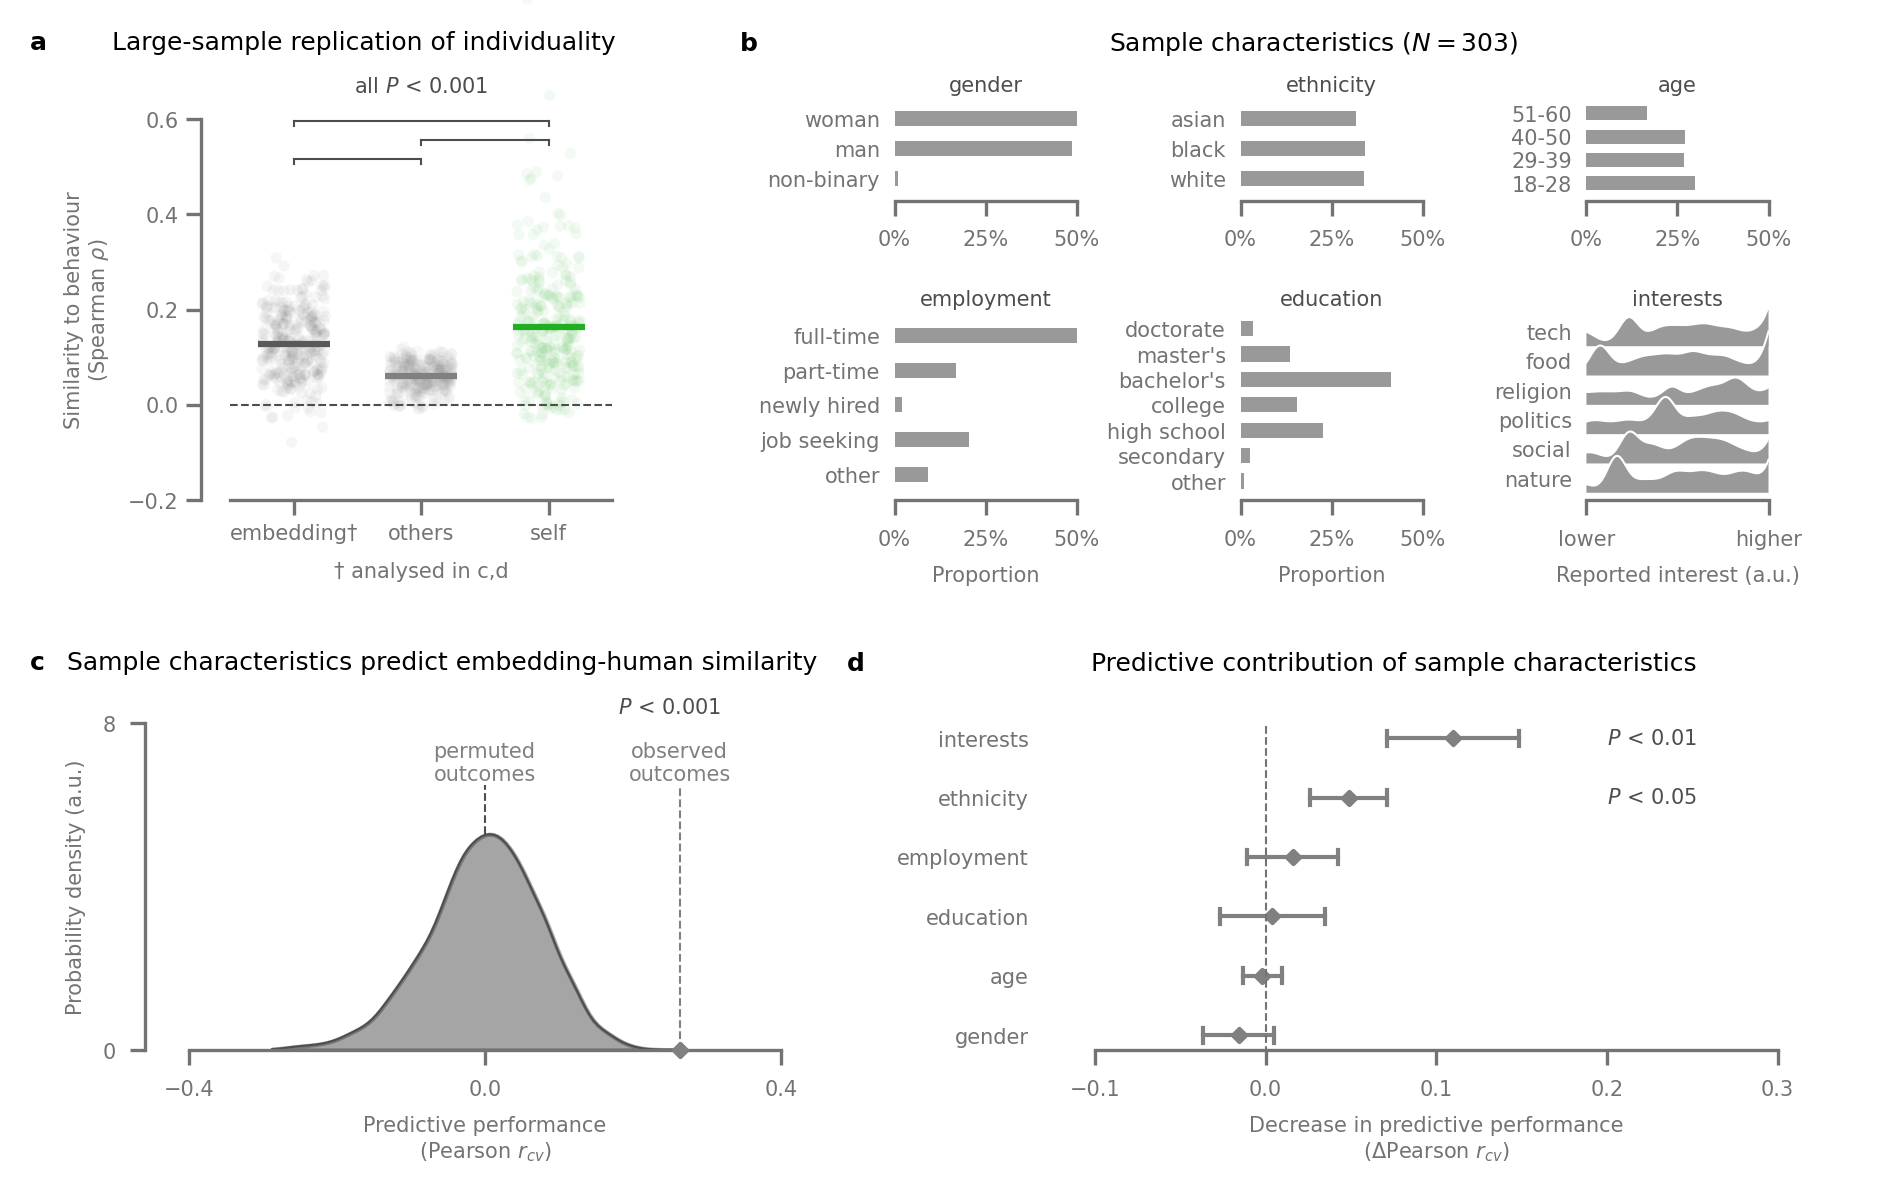

In [20]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.colors import Normalize, TwoSlopeNorm, PowerNorm, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
import matplotlib
import matplotlib.patches as mpatches

hypothesis_test = 'sign'
hypothesis_alternative = 'two-sided'
hypothesis_method = 'holm'
hypothesis_se = 'within'

run = 0
exp = 2
mod = 'glove'
modb = 'glove'

hypothesis_test2 = 'permutation'
hypothesis_alternative2 = 'greater'
hypothesis_method2 = 'holm'
hypothesis_se2 = 'within'

run_dem = 5
order_importance = True
order_dem = [5, 3, 4, 1, 0, 2]

rewrite_labels = {
    'gender': [
        'woman',
        'man',
        'non-binary'
    ],
    'ethnicity': [
        'asian',
        'black',
        'white'
    ],
    'education': [
        'other',
        'secondary',
        'high school',
        'college',
        'bachelor\'s',
        'master\'s',
        'doctorate'
    ],
    'employment': [
        'other',
        'job seeking',
        'newly hired',
        'part-time',
        'full-time'
    ]
}

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

cols2 = np.array([
    plots.colours.CM_RDM_CL(0.00),
    plots.colours.CM_RDM_CL(0.20),
    plots.colours.CM_RDM_CL(0.40)
])

'''
precompute deltas;
these are also required for ordering demographics
'''

out = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run_dem}/tasks/task-masubemb_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))

full = out['r_full'][mod][None,:].cpu().numpy()
perm = out['r_base'][mod][None,:].cpu().numpy()
block = out['r_perm'][mod].cpu().numpy().T

desc_full = model.stats.sample_descriptives(full.T, se = hypothesis_se2)
stat_full = model.stats.sample_tests(
    full.mean() - perm,
    test = hypothesis_test2, alternative = hypothesis_alternative2, 
    method = hypothesis_method2, se = hypothesis_se2
)

model.stats.save_results(desc_full, './deliverable/csv/fig3/all_wthn_desc.csv')
model.stats.save_results(stat_full, './deliverable/csv/fig3/all_wthn_block.csv')

desc_block = model.stats.sample_descriptives((full.mean() - block).T, se = hypothesis_se2)
stat_block = model.stats.sample_tests(
    full.mean() - block,
    test = hypothesis_test2, alternative = hypothesis_alternative2, 
    method = hypothesis_method2, se = hypothesis_se2
)

model.stats.save_results(desc_block, './deliverable/csv/fig3/all_wthn_desc-2.csv')
model.stats.save_results(stat_block, './deliverable/csv/fig3/all_wthn_block-2.csv')

delta = full.mean() - block
labels_D = list(out['labels'].keys())

if order_importance:
    order = delta.mean(1).argsort()
    labels_D = np.array(labels_D)[order].tolist()
else:
    order = np.arange(block.shape[0])

'''
start fig
'''    

fig, ax = plt.subplots(figsize = (6.4, 4.0), dpi = 300)

# remove axis
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.axis('off')

'''
panel A
'''

# reliability data
ax1 = ax.inset_axes([0.105, 0.58, 0.21, 0.35])

R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-mareliability_bse0-{modb}_mod-delta.pt', map_location=torch.device('cpu'))
R_base = R['rho_emb'].squeeze().cpu().numpy().diagonal()
R_indiv = R['rho'].cpu().numpy().diagonal().squeeze()
R_group = R['rho'].cpu().numpy()
R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

R_a = np.array([R_base, R_group, R_indiv])
X_jitter = np.random.uniform(-0.25, 0.25, size = (R_base.shape[0],))

offset = 0

for i, R_i in enumerate(R_a):
    mu = R_i.mean()
    se = model.stats.bootstrap_se(R_i)
    x_i = i + X_jitter
    
    if offset < (mu + 1.96 * se):
        offset = mu + 1.96 * se
    
    ax1.scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i], s = 30, alpha = 0.05, clip_on = False)
    
    '''
    from sklearn.neighbors import KernelDensity
    perm_pad = 0.0
    kde = KernelDensity(bandwidth = 0.005).fit(R_i[:,None])
    scores = kde.score_samples(R_i[:,None])
    scores = np.exp(scores)
    scores = np.abs(scores / np.trapezoid(scores, R_i))
    scores = scores / scores.max()
    scores = 0.50 * scores - 0.225
    x_i = np.array([
        np.random.uniform(low = -0.225, high = scores[i])
        for i in range(len(scores))
    ]) + i
    ax1.scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i], s = 30, alpha = 0.075, clip_on = False)
    '''
    
    ax1.scatter([i], [mu], color = cols[i], marker = '_', s = 300, clip_on = False, zorder = 2)

design = [(1, 0), (2, 1), (2, 0)]
group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(group, './deliverable/csv/fig3/a_wthn_group.csv')
model.stats.save_results(pairwise, './deliverable/csv/fig3/a_wthn_pairs.csv')

# significance
count = 3.5
gain = 0.04
min_p = 0.0

for i, (ii, jj) in enumerate(design):
    p_i = pairwise[i]['p_cor']
    if p_i < .05:
        if p_i > min_p:
            min_p = p_i
        
        sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
        yy = 0.2 + offset + count * gain
        ax1.plot([ii, jj], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        ax1.plot([ii, ii], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        ax1.plot([jj, jj], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        count += 1

rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
ax1.annotate(f'all {rep_p}', xy = (0, 0), xytext = (1.0, 0.6675), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)     

ax1.plot([-0.5, 2.5], [0, 0], color = plots.colours.H2, linewidth = 0.5, linestyle = '--', clip_on = False)

# cosmetics
ax1.set_xlim([-0.5, 2.5])
ax1.set_xticks([0, 1, 2], ['embedding†', 'others', 'self'])
ax1.set_ylim([-0.2, 0.6])
ax1.set_yticks(np.arange(-0.2, 0.61, 0.2))
ax1.set_ylabel('Similarity to behaviour\n' + fr'(Spearman $\rho$)', fontsize = 5)
ax1.spines['left'].set_position(('axes', -0.075))
ax1.tick_params(axis = 'x', labelsize = 5, pad = 2)
ax1.tick_params(axis = 'y', labelsize = 5, pad = 2)
sns.despine(ax = ax1)

ax1.annotate('† analysed in c,d', xy = (0, 0), xytext = (1.0, -0.350), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H3, annotation_clip = False)

'''
panel b
'''

panel_y = 0.58
panel_x = 0.47
panel_c = 3
panel_h = 0.175
panel_w = 0.10
off_w = 0.09
off_h = 0.10
COLD = np.array([0.6, 0.6, 0.6, 1.0])
target = 0.30

demo_ax = []

for i, key in enumerate(L):
    ids = L[key]['ids']
    labels = L[key]['labels']
    
    if key in ['gender', 'ethnicity']:
        ids = ids.flip(-1)
        labels = list(reversed(labels))
    
    oi = order_dem[i]
    j, k = oi % panel_c, oi // panel_c
    
    panel_hh = panel_h
    if key in ['gender', 'ethnicity', 'age']:
        panel_hh = panel_h * 0.55
    
    ax_i = ax.inset_axes([panel_x + (panel_w + off_w) * j, panel_y + (panel_h + off_h) * k, panel_w, panel_hh])
    sns.despine(ax = ax_i)
    
    ax_i.tick_params(axis = 'both', which = 'major', labelsize = 5)
    ax_i.xaxis.label.set_fontsize(5)
    ax_i.yaxis.label.set_fontsize(5)
    
    if task.demographics[key].type == 'categorical':
        # grab rows
        idx = ids.cpu().numpy()
        
        # compute bar width
        if key in ['gender', 'ethnicity']:
            off = target * 0.85
        else:
            curcount = idx.shape[0]
            maxcount = 7
            ratio = target / maxcount
            off = curcount * ratio
        
        
        for m_i in range(idx.shape[0]):
            count = X[:,idx[m_i]].sum() / X.shape[0] * 100
            
            ax_i.fill_between(
                [0, count, count, 0], 
                [m_i - off, m_i - off, m_i + off, m_i + off], 
                edgecolor = 'None', 
                facecolor = COLD,
            )
        
        labels_i = rewrite_labels[key]
        if key in ['gender', 'ethnicity']:
            labels_i = list(reversed(labels_i))
        
        ax_i.set_ylim([-0.75, idx.shape[0] - 0.25])
        ax_i.set_yticks(np.arange(0, len(labels_i), 1), labels = labels_i)
        ax_i.set_xlim([0.0, 50.0])
        ax_i.set_xticks([0.0, 25.0, 50.0], labels = [fr'0%', '25%', '50%'])
        if key in ['employment', 'education']:
            ax_i.set_xlabel(fr'Proportion')
    elif task.demographics[key].type == 'continuous':
        # grab rows
        idx = ids.cpu().numpy()
        
        X_s = X[:,idx].squeeze()
        X_s = mvpy.preprocessing.Scaler().to_numpy().fit_transform(X_s)
        
        if key == 'interests':
            scores = []
            Z_i = np.linspace(-1, 1, 100)
            
            for ii, idx_i in enumerate(idx):
                X_i = X_s[:,ii].squeeze()
                from sklearn.neighbors import KernelDensity
                kde = KernelDensity(bandwidth = 0.1).fit(X_i[:,None])
                scores.append(np.exp(kde.score_samples(Z_i[:,None])))
            
            scores = np.array(scores)
            scores = scores / scores.max()
            scores = 1.5 * scores
            
            for idx_i in range(scores.shape[0]):
                rank = idx_i
                ax_i.fill_between(Z_i, scores[idx_i,:] + rank, rank, edgecolor = 'None', facecolor = COLD)
                ax_i.plot(Z_i, scores[idx_i,:] + rank, color = 'white', lw = 0.5)
            
            ax_i.set_xlim([-1, 1])
            ax_i.set_xticks([-1, 1], labels = ['lower', 'higher'])
            ax_i.set_xlabel(fr'Reported interest (a.u.)', fontsize = 5)
            ax_i.set_ylim([-0.25, idx.shape[0] + 0.25])
            ax_i.set_yticks(np.arange(0, 6, 1) + 0.5, labels = ['nature', 'social', 'politics', 'religion', 'food', 'tech'])
        elif key == 'age':
            import math
            bins = 4
            
            # compute bar width
            #curcount = bins
            #maxcount = 7
            #ratio = target / maxcount
            #off = curcount * ratio
            off = target * 1.0
            
            # compute bin size
            vmin, vmax =  X[:,0].min(),  X[:,0].max()
            D = vmax - vmin + 1
            D = D / bins
            D = math.ceil(D)
            
            X_i = X[:,ids[0].cpu().numpy()]
            
            xV = []
            xL = []
            
            for m_i in range(bins):
                s = vmin + m_i * D
                e = vmin + (m_i + 1) * D
                
                count = ((X_i >= s) & (X_i < e)).sum()
                count = count / X.shape[0] * 100
                
                ax_i.fill_between(
                    [0, count, count, 0], 
                    [m_i - off, m_i - off, m_i + off, m_i + off], 
                    edgecolor = 'None', 
                    facecolor = COLD,
                )
                
                xV.append(m_i)
                xL.append(f'{int(s)}-{int(min(e - 1, vmax))}')
            
            ax_i.set_ylim([-0.75, bins - 0.25])
            ax_i.set_yticks(np.arange(0, bins, 1), labels = xL)
            ax_i.set_xlim([0.0, 50.0])
            ax_i.set_xticks([0.0, 25.0, 50.0], labels = [fr'0%', '25%', '50%'])
            
    
    ax_i.set_title(fr'{key}', fontsize = 5, fontweight = 'normal', color = plots.colours.H2, pad = 0)
    ax_i.spines['left'].set_visible(False)
    ax_i.tick_params(axis = 'y', which = 'both', length = 0)
    ax_i.tick_params(axis = 'y', which = 'major', labelsize = 5)
    
    demo_ax.append(ax_i)

'''
panel c + d
'''

# full model
ax2 = ax.inset_axes([0.0825, 0.075, 0.325, 0.30])

from sklearn.neighbors import KernelDensity
perm_pad = 0.0
kde = KernelDensity(bandwidth = 0.015).fit(perm.T)
x_i = np.linspace(perm.min() - perm_pad, perm.max() + perm_pad, 100)
scores = kde.score_samples(x_i[:,None])
scores = np.exp(scores)
scores = scores / np.trapezoid(scores, x_i)

min_p = stat_full[0]['p_cor']
rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'

ax2.plot(x_i, scores, color = plots.colours.H2, linewidth = 0.5)
ax2.fill_between(x_i, scores, color = plots.colours.H2, alpha = 0.5)
ax2.plot([full.mean(), full.mean()], [0.0, 6.5], color = cols[1], linewidth = 0.5, linestyle = '--')
ax2.scatter([full.mean()], [0.0], marker = 'D', s = 5, color = cols[1], clip_on = False, zorder = 5)
ax2.annotate('observed\noutcomes', xy = (0, 0), xytext = (full.mean(), 6.5), ha = 'center', va = 'bottom', color = cols[1], fontsize = 5)

ax2.plot([perm.mean(), perm.mean()], [scores.max(), 6.5], color = plots.colours.H2, linewidth = 0.5, linestyle = '--')
ax2.annotate('permuted\noutcomes', xy = (0, 0), xytext = (perm.mean(), 6.5), ha = 'center', va = 'bottom', color = cols[1], fontsize = 5)

ax2.annotate(f'{rep_p}', xy = (0, 0), xytext = (0.25, 8.15), ha = 'center', va = 'bottom', color = plots.colours.H2, fontsize = 5)

ax2.set_xlim([-0.4, 0.4])
ax2.set_xticks([-0.4, 0.0, 0.4])
ax2.set_xlabel('Predictive performance\n' + fr'(Pearson $r_{{cv}}$)', fontsize = 5)
ax2.set_ylim([0.0, 8.0])
ax2.set_yticks([0, 8])
ax2.set_ylabel(fr'Probability density (a.u.)', fontsize = 5)

sns.despine(ax = ax2)
ax2.spines['left'].set_position(('axes', -0.075))

# individual blocks
ax3 = ax.inset_axes([0.58, 0.075, 0.375, 0.30])

order_importance = True
bar_size = 0.125
bar_ci = 1.96
lw = 1.0

min_p = 1.0
    
for ii, i in enumerate(order[::-1]):
    mu = delta[i].mean()
    se = np.std(delta[i])
    
    ii = block.shape[0] - ii - 1
    xs, xe = ii - bar_size, ii + bar_size
    
    pval = stat_block[i]['p_cor']
    min_p = pval
    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
    if pval <= 0.05:
        ax3.annotate(f'{rep_p}', xy = (0, 0), xytext = (0.2, ii), ha = 'left', va = 'center', color = plots.colours.H2, fontsize = 5)

    color = cols[1]
    bar_col = cols[1]
    
    ax3.plot([mu - bar_ci * se, mu + bar_ci * se], [ii, ii], color = bar_col, linewidth = lw, zorder = 1)
    ax3.plot([mu - bar_ci * se, mu - bar_ci * se], [ii - bar_size, ii + bar_size], color = bar_col, linewidth = lw, zorder = 1)
    ax3.plot([mu + bar_ci * se, mu + bar_ci * se], [ii - bar_size, ii + bar_size], color = bar_col, linewidth = lw, zorder = 1)
    ax3.scatter([mu], [ii], color = color, marker = 'D', s = 5, zorder = 2)

ax3.plot([0, 0], [-0.5, 5.5], color = plots.colours.H3, linewidth = 0.5, linestyle = '--')

ax3.set_ylim([-0.25, 5.25])
ax3.set_xlim([-0.1, 0.3])
ax3.set_yticks(np.arange(delta.shape[0]), labels = labels_D, fontsize = 5)
ax3.set_xticks(np.arange(-0.1, 0.31, 0.1))

ax3.set_xlabel('Decrease in predictive performance\n' + fr'($\Delta$Pearson $r_{{cv}}$)', fontsize = 5)

sns.despine(ax = ax3)
ax3.spines['left'].set_position(('axes', -0.075))
ax3.spines['left'].set_visible(False)
ax3.tick_params(axis = 'y', which = 'both', length = 0)

ax3.tick_params(axis = 'both', which = 'both', labelsize = 5)
ax3.xaxis.label.set_fontsize(5)
ax3.yaxis.label.set_fontsize(5)

ax2.tick_params(axis = 'both', which = 'both', labelsize = 5)
ax2.xaxis.label.set_fontsize(5)
ax2.yaxis.label.set_fontsize(5)

'''
cosmetics
'''

# colors
for ax_i in [ax1, *demo_ax, ax2, ax3]:
    ax_i.yaxis.label.set_color(plots.colours.H3)
    ax_i.xaxis.label.set_color(plots.colours.H3)
    ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', which = 'minor', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', which = 'major', colors = plots.colours.H3)
    ax_i.spines['bottom'].set_color(plots.colours.H3)
    ax_i.spines['left'].set_color(plots.colours.H3)

# labels
ax1.annotate('a', xy = (0, 0), xytext = (-2.00, 0.760), ha = 'center', va = 'center', fontsize = 6, fontweight = 'bold', annotation_clip = False)
ax1.annotate('Large-sample replication of individuality', xy = (0, 0), xytext = (0.55, 0.760), ha = 'center', va = 'center', fontsize = 6, annotation_clip = False)

demo_ax[2].annotate('b', xy = (0, 0), xytext = (-135.0, 4.5), ha = 'center', va = 'center', fontsize = 6, fontweight = 'bold', annotation_clip = False)
demo_ax[2].annotate('Sample characteristics ($N = 303$)', xy = (0, 0), xytext = (20.0, 4.5), ha = 'center', va = 'center', fontsize = 6, annotation_clip = False)

ax2.annotate('c', xy = (0, 0), xytext = (-0.605, 9.5), ha = 'center', va = 'center', fontsize = 6, fontweight = 'bold', annotation_clip = False)
ax2.annotate('Sample characteristics predict embedding-human similarity', xy = (0, 0), xytext = (-0.0575, 9.5), ha = 'center', va = 'center', fontsize = 6, annotation_clip = False)

ax3.annotate('d', xy = (0, 0), xytext = (-0.24, 6.25), ha = 'center', va = 'center', fontsize = 6, fontweight = 'bold', annotation_clip = False)
ax3.annotate('Predictive contribution of sample characteristics', xy = (0, 0), xytext = (0.075, 6.25), ha = 'center', va = 'center', fontsize = 6, annotation_clip = False)

fig.tight_layout()

#ax.axis('on')

fig.savefig('./deliverable/png/fig3.png', dpi = 900, format = 'png')
fig.savefig('./deliverable/pdf/fig3.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/fig3.svg', dpi = 900, format = 'svg')

In [18]:
# grab ceiling estimate
ceil = out['r_ceil'][mod]
ceil.mean(), 1.96 * ceil.std()

(tensor(0.9165), tensor(0.0147))